## 위치 인코딩

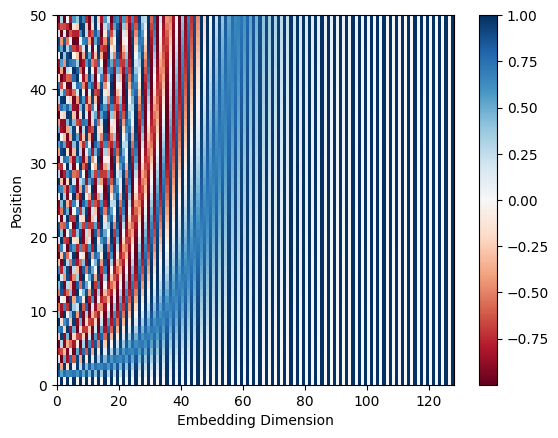

In [ ]:
import math
import torch
from torch import nn
from matplotlib import pyplot as plt

class PositionalEncoding(nn.Module):
  def __init__(self, d_model, dropout=0.1, max_len=5000):
    super().__init__()
    self.dropout = nn.Dropout(p=dropout)

    position=torch.arange(max_len).unsqueeze(1)
    div_term=torch.exp(torch.arange(0,d_model,2)*(-math.log(10000.0)/d_model))

    pe=torch.zeros(max_len,1,d_model)
    pe[:,0,0::2]=torch.sin(position*div_term)
    pe[:,0,1::2]=torch.cos(position*div_term)
    self.register_buffer("pe", pe)

  def forward(self, x):
    x=x+self.pe[: x.size(0)]
    return self.dropout(x)

encoding=PositionalEncoding(d_model=128, max_len=50)

plt.pcolormesh(encoding.pe.numpy().squeeze(), cmap="RdBu")
plt.xlabel("Embedding Dimension")
plt.xlim((0,128))
plt.ylabel("Position")
plt.colorbar()
plt.show()

## 트랜스포머 - 영어 독일어 번역 모델

대규모 다국어 데이터 세트인 Multi30K 데이터 세트 사용


In [1]:
pip install torchdata torchtext portalocker

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchtext]


* torch data 라이브러리: 대규모 데이터 세트를 다루기 쉽게 데티러르 불러오고 변환, 배치하는 api 제공
* torchtext 라이브러리: 파이토치를 위한 텍스트 처리 라이브러리
* portalocker 라이브러리: 파일 락을 관리, 여러 프로세스 간에 동시에 파일을 수정하거나 읽는 것을 방지

In [7]:
!python -m spacy download de_core_news_sm
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.6/14.6 MB 32.7 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 44.8 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [43]:

import gzip
import os
import urllib.request
from collections import Counter
import spacy

# 언어 설정
SRC_LANGUAGE = "de"
TGT_LANGUAGE = "en"

UNK_IDX, PAD_IDX, BOS_IDX, EOS_IDX = 0, 1, 2, 3
special_symbols = ["<unk>", "<pad>", "<bos>", "<eos>"]

# 1. Multi30k 데이터셋 다운로드
os.makedirs("data", exist_ok=True)

base_url = "https://raw.githubusercontent.com/multi30k/dataset/master/data/task1/raw/"

for lang in [SRC_LANGUAGE, TGT_LANGUAGE]:
    path = f"data/train.{lang}.gz"

    if not os.path.exists(path):
        urllib.request.urlretrieve(
            base_url + f"train.{lang}.gz",
            path
        )

# 2. Multi30k 데이터셋 로드

def load_multi30k(split="train"):
    if split not in ["train", "val", "test"]:
        raise ValueError("split은 train, val, test 중 하나여야 합니다.")

    os.makedirs("data", exist_ok=True)

    paths = {}

    for lang in [SRC_LANGUAGE, TGT_LANGUAGE]:
        path = f"data/{split}.{lang}.gz"

        if not os.path.exists(path):
            url = base_url + f"{split}.{lang}.gz"
            urllib.request.urlretrieve(url, path)

        paths[lang] = path

    with gzip.open(paths[SRC_LANGUAGE], "rt", encoding="utf-8") as src_file, \
         gzip.open(paths[TGT_LANGUAGE], "rt", encoding="utf-8") as tgt_file:

        for src, tgt in zip(src_file, tgt_file):
            yield src.strip(), tgt.strip()


# 3. spaCy 토크나이저 생성
spacy_de = spacy.load("de_core_news_sm")
spacy_en = spacy.load("en_core_web_sm")

token_transform = {
    SRC_LANGUAGE: lambda text: [
        token.text for token in spacy_de.tokenizer(text)
    ],
    TGT_LANGUAGE: lambda text: [
        token.text for token in spacy_en.tokenizer(text)
    ]
}

print("Token Transform:")
print(token_transform)

# 4. 토큰 생성
def generate_tokens(text_iter, language):
    language_index = {
        SRC_LANGUAGE: 0,
        TGT_LANGUAGE: 1
    }

    for text in text_iter:
        yield token_transform[language](
            text[language_index[language]]
        )

# 5. torchtext 대체 어휘 사전 클래스
class Vocabulary:
    def __init__(self, token_iterator, specials, min_freq=1):
        counter = Counter()

        for tokens in token_iterator:
            counter.update(tokens)

        self.itos = list(specials)

        # 빈도 내림차순, 동일 빈도는 사전순 정렬
        for token, freq in sorted(
            counter.items(),
            key=lambda x: (-x[1], x[0])
        ):
            if freq >= min_freq and token not in specials:
                self.itos.append(token)

        self.stoi = {
            token: idx for idx, token in enumerate(self.itos)
        }

        self.default_index = None

    def set_default_index(self, index):
        self.default_index = index

    def __getitem__(self, token):
        if token in self.stoi:
            return self.stoi[token]

        if self.default_index is not None:
            return self.default_index

        raise KeyError(token)

    def __len__(self):
        return len(self.itos)

    def get_itos(self):
        return self.itos

    def get_stoi(self):
        return self.stoi

    def lookup_indices(self, tokens):
        return [self[token] for token in tokens]

    def lookup_tokens(self, indices):
        return [self.itos[idx] for idx in indices]

# 6. 어휘 사전 생성
vocab_transform = {}

for language in [SRC_LANGUAGE, TGT_LANGUAGE]:
    train_iter = load_multi30k()

    vocab_transform[language] = Vocabulary(
        generate_tokens(train_iter, language),
        specials=special_symbols,
        min_freq=1
    )

    vocab_transform[language].set_default_index(UNK_IDX)

print("Vocab Transform:")
print(vocab_transform)

# 7. 결과 확인
print("독일어 단어 수:", len(vocab_transform[SRC_LANGUAGE]))
print("영어 단어 수:", len(vocab_transform[TGT_LANGUAGE]))

print("영어 특수 토큰:",
      vocab_transform[TGT_LANGUAGE].get_itos()[:4])

print("hello 인덱스:",
      vocab_transform[TGT_LANGUAGE]["hello"])


Token Transform:
{'de': <function <lambda> at 0x7bd6f8fefec0>, 'en': <function <lambda> at 0x7bd6f8feff60>}
Vocab Transform:
{'de': <__main__.Vocabulary object at 0x7bd700aab230>, 'en': <__main__.Vocabulary object at 0x7bd6f40ffed0>}
독일어 단어 수: 19214
영어 단어 수: 10837
영어 특수 토큰: ['<unk>', '<pad>', '<bos>', '<eos>']
hello 인덱스: 5465


In [35]:
# 트랜스포머 모델 구성
import math
import torch
from torch import nn

class PositionalEncoding(nn.Module):
  def __init__(self, d_model, max_len, dropout=0.1):
    super().__init__()
    self.dropout=nn.Dropout(p=dropout)

    position=torch.arange(max_len).unsqueeze(1)
    div_term=torch.exp(
        torch.arange(0, d_model,2)*(-math.log(10000.0)/d_model)
    )
    pe=torch.zeros(max_len,1,d_model )
    pe[:,0,0::2]=torch.sin(position*div_term)
    pe[:,0,1::2]=torch.cos(position*div_term)
    self.register_buffer("pe", pe)


  def forward(self, x):
    x=x+self.pe[: x.size(0)]
    return self.dropout(x)

class TokenEmbedding(nn.Module):
  def __init__(self, vocab_size, emb_size):
    super().__init__()
    self.embedding=nn.Embedding(vocab_size, emb_size)
    self.emb_size=emb_size

  def forward(slef, tokens):
    return self.embedding(tokens.long())* math.sqrt(self.emb_size)

# 소스 데이터 + 입력 데이터 -> 입력 임베딩으로 변환
# src_tok_emb, tgt_tok_emb 생성
class Seq2SeqTransformer(nn.Module):
  def __init__(
      self, num_encoder_layers, num_decoder_layers,
      emb_size,max_len, nhead, src_vocab_size, tgt_vocab_size,
      dim_feedforward, dropout=0.1
  ):
    super().__init__()

    # PositionalEmbedding 적용
    self.src_tok_emb=TokenEmbedding(src_vocab_size, emb_size)
    self.tgt_tok_emb=TokenEmbedding(tgt_vocab_size, emb_size)
    self.positional_encoding=PositionalEncoding(
        emb_size, max_len=5000, dropout=dropout
    )

    # 파이토치에서 제공해주는 transformer 클래스 적용
    self.transformer=nn.Transformer(
        d_model=emb_size,
        nhead=nhead,
        num_encoder_layers=num_encoder_layers,
        num_decoder_layers=num_decoder_layers,
        dim_feedforward=dim_feedforward,
        dropout=dropout
    )
    # 선형 변환
    self.generator=nn.Linear(emb_size, tgt_vocab_size)

  def forward(
      self, src, tgt, src_mask, tgt_mask,
      src_padding_mask, tgt_padding_mask, memory_key_padding_mask
  ):
    src_emb=self.positional_encoding(self.src_tok_emb(src))
    tgt_emb=self.positional_encoding(self.tgt_tok_emb(tgt))
    outs=self.transformer(
        src_emb, tgt_emb, src_mask, tgt_mask,
        None, src_padding_mask, tgt_padding_mask,
        memory_key_padding_mask
    )
    return self.generator(outs)

  def encode(self, src, src_mask):
    return self.transformer.encoder(
        self.positional_encoding(self.src_tok_emb(src)), src_mask)

  def decode(self, tgt, memory, tgt_mask):
    return self.transformer.decoder(
        self.positional_encoding(self.tgt_tok_emb(tgt)),
        memory, tgt_mask)


In [ ]:
# 트랜스포머 클래스
transformer = torch.nn.Transformer(
    d_model=512,
    nhead=8,
    num_encoder_layers=6,
    num_decoder_layers=6,
    dim_feedforward=2048,
    dropout=0.1,
    activation=torch.nn.functional.relu,
    layer_norm_eps=1e-05,
)

In [ ]:
# 순방향 클래스
output = transformer.forward(
    src,
    tgt,
    src_mask=None,
    tgt_mask=None,
    memory_mask=None,
    src_key_padding_mask=None,
    tgt_key_padding_mask=None,
    memory_key_padding_mask=None,
)

In [37]:
#트랜스포머 모델 구조
from torch import optim

BATCH_SIZE=128
DEVICE="cuda" if torch.cuda.is_available() else "cpu"

model= Seq2SeqTransformer(
    num_encoder_layers=3,
    num_decoder_layers=3,
    emb_size=512,
    max_len=512,
    nhead=8,
    src_vocab_size=len(vocab_transform[SRC_LANGUAGE]),
    tgt_vocab_size=len(vocab_transform[TGT_LANGUAGE]),
    dim_feedforward=512,
).to(DEVICE)

criterion=nn.CrossEntropyLoss(ignore_index=PAD_IDX).to(DEVICE)
optimizer=optim.Adam(model.parameters())

for main_name, main_module in model.named_children():
  print(main_name)
  for sub_name, sub_module in main_module.named_children():
    print("ㄴ", sub_name)
    for ssub_name, ssub_module in sub_module.named_children():
      print("| ㄴ", ssub_name)
      for sssub_name, sssub_module in ssub_module.named_children():
        print("| | ㄴ", sssub_name)

# 출력결과
# 인코더 디코더: 각각 3개의 계층

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:145: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.encoder = TransformerEncoder(


src_tok_emb
ㄴ embedding
tgt_tok_emb
ㄴ embedding
positional_encoding
ㄴ dropout
transformer
ㄴ encoder
| ㄴ layers
| | ㄴ 0
| | ㄴ 1
| | ㄴ 2
| ㄴ norm
ㄴ decoder
| ㄴ layers
| | ㄴ 0
| | ㄴ 1
| | ㄴ 2
| ㄴ norm
generator


In [46]:

import torch
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence

# 배치 크기
BATCH_SIZE = 32

# 여러 변환 함수를 순차적으로 적용
def sequential_transforms(*transforms):
    def func(txt_input):
        for transform in transforms:
            txt_input = transform(txt_input)
        return txt_input
    return func

# BOS, EOS 토큰 추가
def input_transform(token_ids):
    return torch.cat(
        (
            torch.tensor([BOS_IDX]),
            torch.tensor(token_ids),
            torch.tensor([EOS_IDX])
        )
    )

# 배치 데이터 생성
def collator(batch):
    src_batch, tgt_batch = [], []

    for src_sample, tgt_sample in batch:
        src_batch.append(
            text_transform[SRC_LANGUAGE](src_sample.rstrip("\n"))
        )
        tgt_batch.append(
            text_transform[TGT_LANGUAGE](tgt_sample.rstrip("\n"))
        )

    # 문장 길이를 맞추기 위한 Padding
    src_batch = pad_sequence(
        src_batch,
        padding_value=PAD_IDX
    )

    tgt_batch = pad_sequence(
        tgt_batch,
        padding_value=PAD_IDX
    )

    return src_batch, tgt_batch

# 텍스트 변환 함수 생성
text_transform = {}

for language in [SRC_LANGUAGE, TGT_LANGUAGE]:
    text_transform[language] = sequential_transforms(
        token_transform[language],
        vocab_transform[language].lookup_indices,
        input_transform
    )

# 검증 데이터셋 로드
data_iter = list(load_multi30k(split="val"))

# DataLoader 생성
dataloader = DataLoader(
    data_iter,
    batch_size=BATCH_SIZE,
    collate_fn=collator
)

# 첫 번째 배치 가져오기
source_tensor, target_tensor = next(iter(dataloader))

print("(source, target):")
print(data_iter[0])

print("source_batch:", source_tensor.shape)
print(source_tensor)

print("target_batch:", target_tensor.shape)
print(target_tensor)


(source, target):
('Eine Gruppe von Männern lädt Baumwolle auf einen Lastwagen', 'A group of men are loading cotton onto a truck')
source_batch: torch.Size([30, 32])
tensor([[    2,     2,     2,     2,     2,     2,     2,     2,     2,     2,
             2,     2,     2,     2,     2,     2,     2,     2,     2,     2,
             2,     2,     2,     2,     2,     2,     2,     2,     2,     2,
             2,     2],
        [   14,     5,     5,    21,     5,    14,     5,     5,     5,    14,
             5,    14,    60,    14,    14,    60,     5,    14,    14,    60,
             5,    17,     5,     5,   303,    21,     5,    60,    14,     5,
             5,    14],
        [   38,    12,    35,    31,    12,    17,   175,    75,    12,   755,
            69,    68,   114,    17,    17,    54,     0,    38,    85,    27,
          1268,     9,    12,   706,    53,   123,  7835,    31,    68,  1428,
           180,    68],
        [   24,   281,    10,   957,    10,     7, 

## GPT 모델 실습

In [48]:
from transformers import GPT2LMHeadModel

model=GPT2LMHeadModel.from_pretrained(pretrained_model_name_or_path="gpt2")

for main_name, main_module in model.named_children():
  print(main_name)
  for sub_name, sub_module in main_module.named_children():
    print("ㄴ", sub_name)
    for ssub_name, ssub_module in sub_module.named_children():
      print("| ㄴ", ssub_name)
      for sssub_name, sssub_module in ssub_module.named_children():
        print("| | ㄴ", sssub_name)


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

transformer
ㄴ wte
ㄴ wpe
ㄴ drop
ㄴ h
| ㄴ 0
| | ㄴ ln_1
| | ㄴ attn
| | ㄴ ln_2
| | ㄴ mlp
| ㄴ 1
| | ㄴ ln_1
| | ㄴ attn
| | ㄴ ln_2
| | ㄴ mlp
| ㄴ 2
| | ㄴ ln_1
| | ㄴ attn
| | ㄴ ln_2
| | ㄴ mlp
| ㄴ 3
| | ㄴ ln_1
| | ㄴ attn
| | ㄴ ln_2
| | ㄴ mlp
| ㄴ 4
| | ㄴ ln_1
| | ㄴ attn
| | ㄴ ln_2
| | ㄴ mlp
| ㄴ 5
| | ㄴ ln_1
| | ㄴ attn
| | ㄴ ln_2
| | ㄴ mlp
| ㄴ 6
| | ㄴ ln_1
| | ㄴ attn
| | ㄴ ln_2
| | ㄴ mlp
| ㄴ 7
| | ㄴ ln_1
| | ㄴ attn
| | ㄴ ln_2
| | ㄴ mlp
| ㄴ 8
| | ㄴ ln_1
| | ㄴ attn
| | ㄴ ln_2
| | ㄴ mlp
| ㄴ 9
| | ㄴ ln_1
| | ㄴ attn
| | ㄴ ln_2
| | ㄴ mlp
| ㄴ 10
| | ㄴ ln_1
| | ㄴ attn
| | ㄴ ln_2
| | ㄴ mlp
| ㄴ 11
| | ㄴ ln_1
| | ㄴ attn
| | ㄴ ln_2
| | ㄴ mlp
ㄴ ln_f
lm_head


In [50]:
#gpt2를 이용한 문장 생성
from transformers import pipeline

generator=pipeline(task="text-generation", model="gpt2")
outputs=generator(
    text_inputs="Machine learning is",
    max_length=20,
    num_return_sequences=3,
    pad_token_id=generator.tokenizer.eos_token_id
  )

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [51]:
# CoLA 데이터세트 불러오기
import torch
from torchtext.datasets import CoLA
from transformers import AutoTokenizer
from torch.utils.data import DataLoader


def collator(batch, tokenizer, device):
    source, labels, texts = zip(*batch)

    tokenized = tokenizer(
        texts,
        padding="longest",
        truncation=True,
        return_tensors="pt"
    )

    input_ids = tokenized["input_ids"].to(device)
    attention_mask = tokenized["attention_mask"].to(device)
    labels = torch.tensor(labels, dtype=torch.long).to(device)

    return input_ids, attention_mask, labels


train_data = list(CoLA(split="train"))
valid_data = list(CoLA(split="dev"))
test_data = list(CoLA(split="test"))

tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token

epochs = 3
batch_size = 16
device = "cuda" if torch.cuda.is_available() else "cpu"

train_dataloader = DataLoader(
    train_data,
    batch_size=batch_size,
    collate_fn=lambda x: collator(x, tokenizer, device),
    shuffle=True,
)

valid_dataloader = DataLoader(
    valid_data,
    batch_size=batch_size,
    collate_fn=lambda x: collator(x, tokenizer, device)
)

test_dataloader = DataLoader(
    test_data,
    batch_size=batch_size,
    collate_fn=lambda x: collator(x, tokenizer, device)
)

print("Train Dataset Length :", len(train_data))
print("Valid Dataset Length :", len(valid_data))
print("Test Dataset Length :", len(test_data))


ImportError: cannot import name 'CoLA' from 'torchtext.datasets' (/usr/local/lib/python3.13/dist-packages/torchtext/datasets/__init__.py)

In [52]:

import numpy as np
from torch import nn

def calc_accuracy(preds, labels):
    pred_flat = np.argmax(preds, axis=1).flatten()
    labels_flat = labels.flatten()
    return np.sum(pred_flat == labels_flat) / len(labels_flat)


def train(model, optimizer, dataloader):
    model.train()
    train_loss = 0.0

    for input_ids, attention_mask, labels in dataloader:
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss = train_loss / len(dataloader)
    return train_loss


def evaluation(model, dataloader):
    with torch.no_grad():
        model.eval()
        criterion = nn.CrossEntropyLoss()
        val_loss, val_accuracy = 0.0, 0.0

        for input_ids, attention_mask, labels in dataloader:
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            logits = outputs.logits

            loss = criterion(logits, labels)
            logits = logits.detach().cpu().numpy()
            label_ids = labels.to("cpu").numpy()
            accuracy = calc_accuracy(logits, label_ids)

            val_loss += loss
            val_accuracy += accuracy

    val_loss = val_loss / len(dataloader)
    val_accuracy = val_accuracy / len(dataloader)
    return val_loss, val_accuracy


best_loss = 10000

for epoch in range(epochs):
    train_loss = train(model, optimizer, train_dataloader)
    val_loss, val_accuracy = evaluation(model, valid_dataloader)

    print(
        f"Epoch {epoch + 1}: "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    if val_loss < best_loss:
        best_loss = val_loss
        torch.save(
            model.state_dict(),
            "./models/GPT2ForSequenceClassification.pt"
        )
        print("Saved the model weights")


NameError: name 'epochs' is not defined

In [53]:
model = GPT2ForSequenceClassification.from_pretrained(
    pretrained_model_name_or_path="gpt2",
    num_labels=2
).to(device)

model.config.pad_token_id = model.config.eos_token_id

model.load_state_dict(
    torch.load("./models/GPT2ForSequenceClassification.pt",
               map_location=device,
               weights_only=True)
)

test_loss, test_accuracy = evaluation(model, test_dataloader)

print(f"Test Loss : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")


NameError: name 'GPT2ForSequenceClassification' is not defined